<>:1010: SyntaxWarning: invalid escape sequence '\s'
<>:1010: SyntaxWarning: invalid escape sequence '\s'
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_11348\2294001330.py:1010: SyntaxWarning: invalid escape sequence '\s'
  cross = pd.read_csv('crsx.dat', delimiter='\s+', header=None)


Menghitung jarak kota terdekat...
Selesai!


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_11348\2294001330.py:609: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  magnitude_summary = (data.groupby([data['Tanggal'], 'Magnitude Category'])
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_11348\2294001330.py:615: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  depth_summary = (data.groupby([data['Tanggal'], 'Depth Category'])
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_11348\2294001330.py:760: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()
C:\Users\LENOVO\AppD

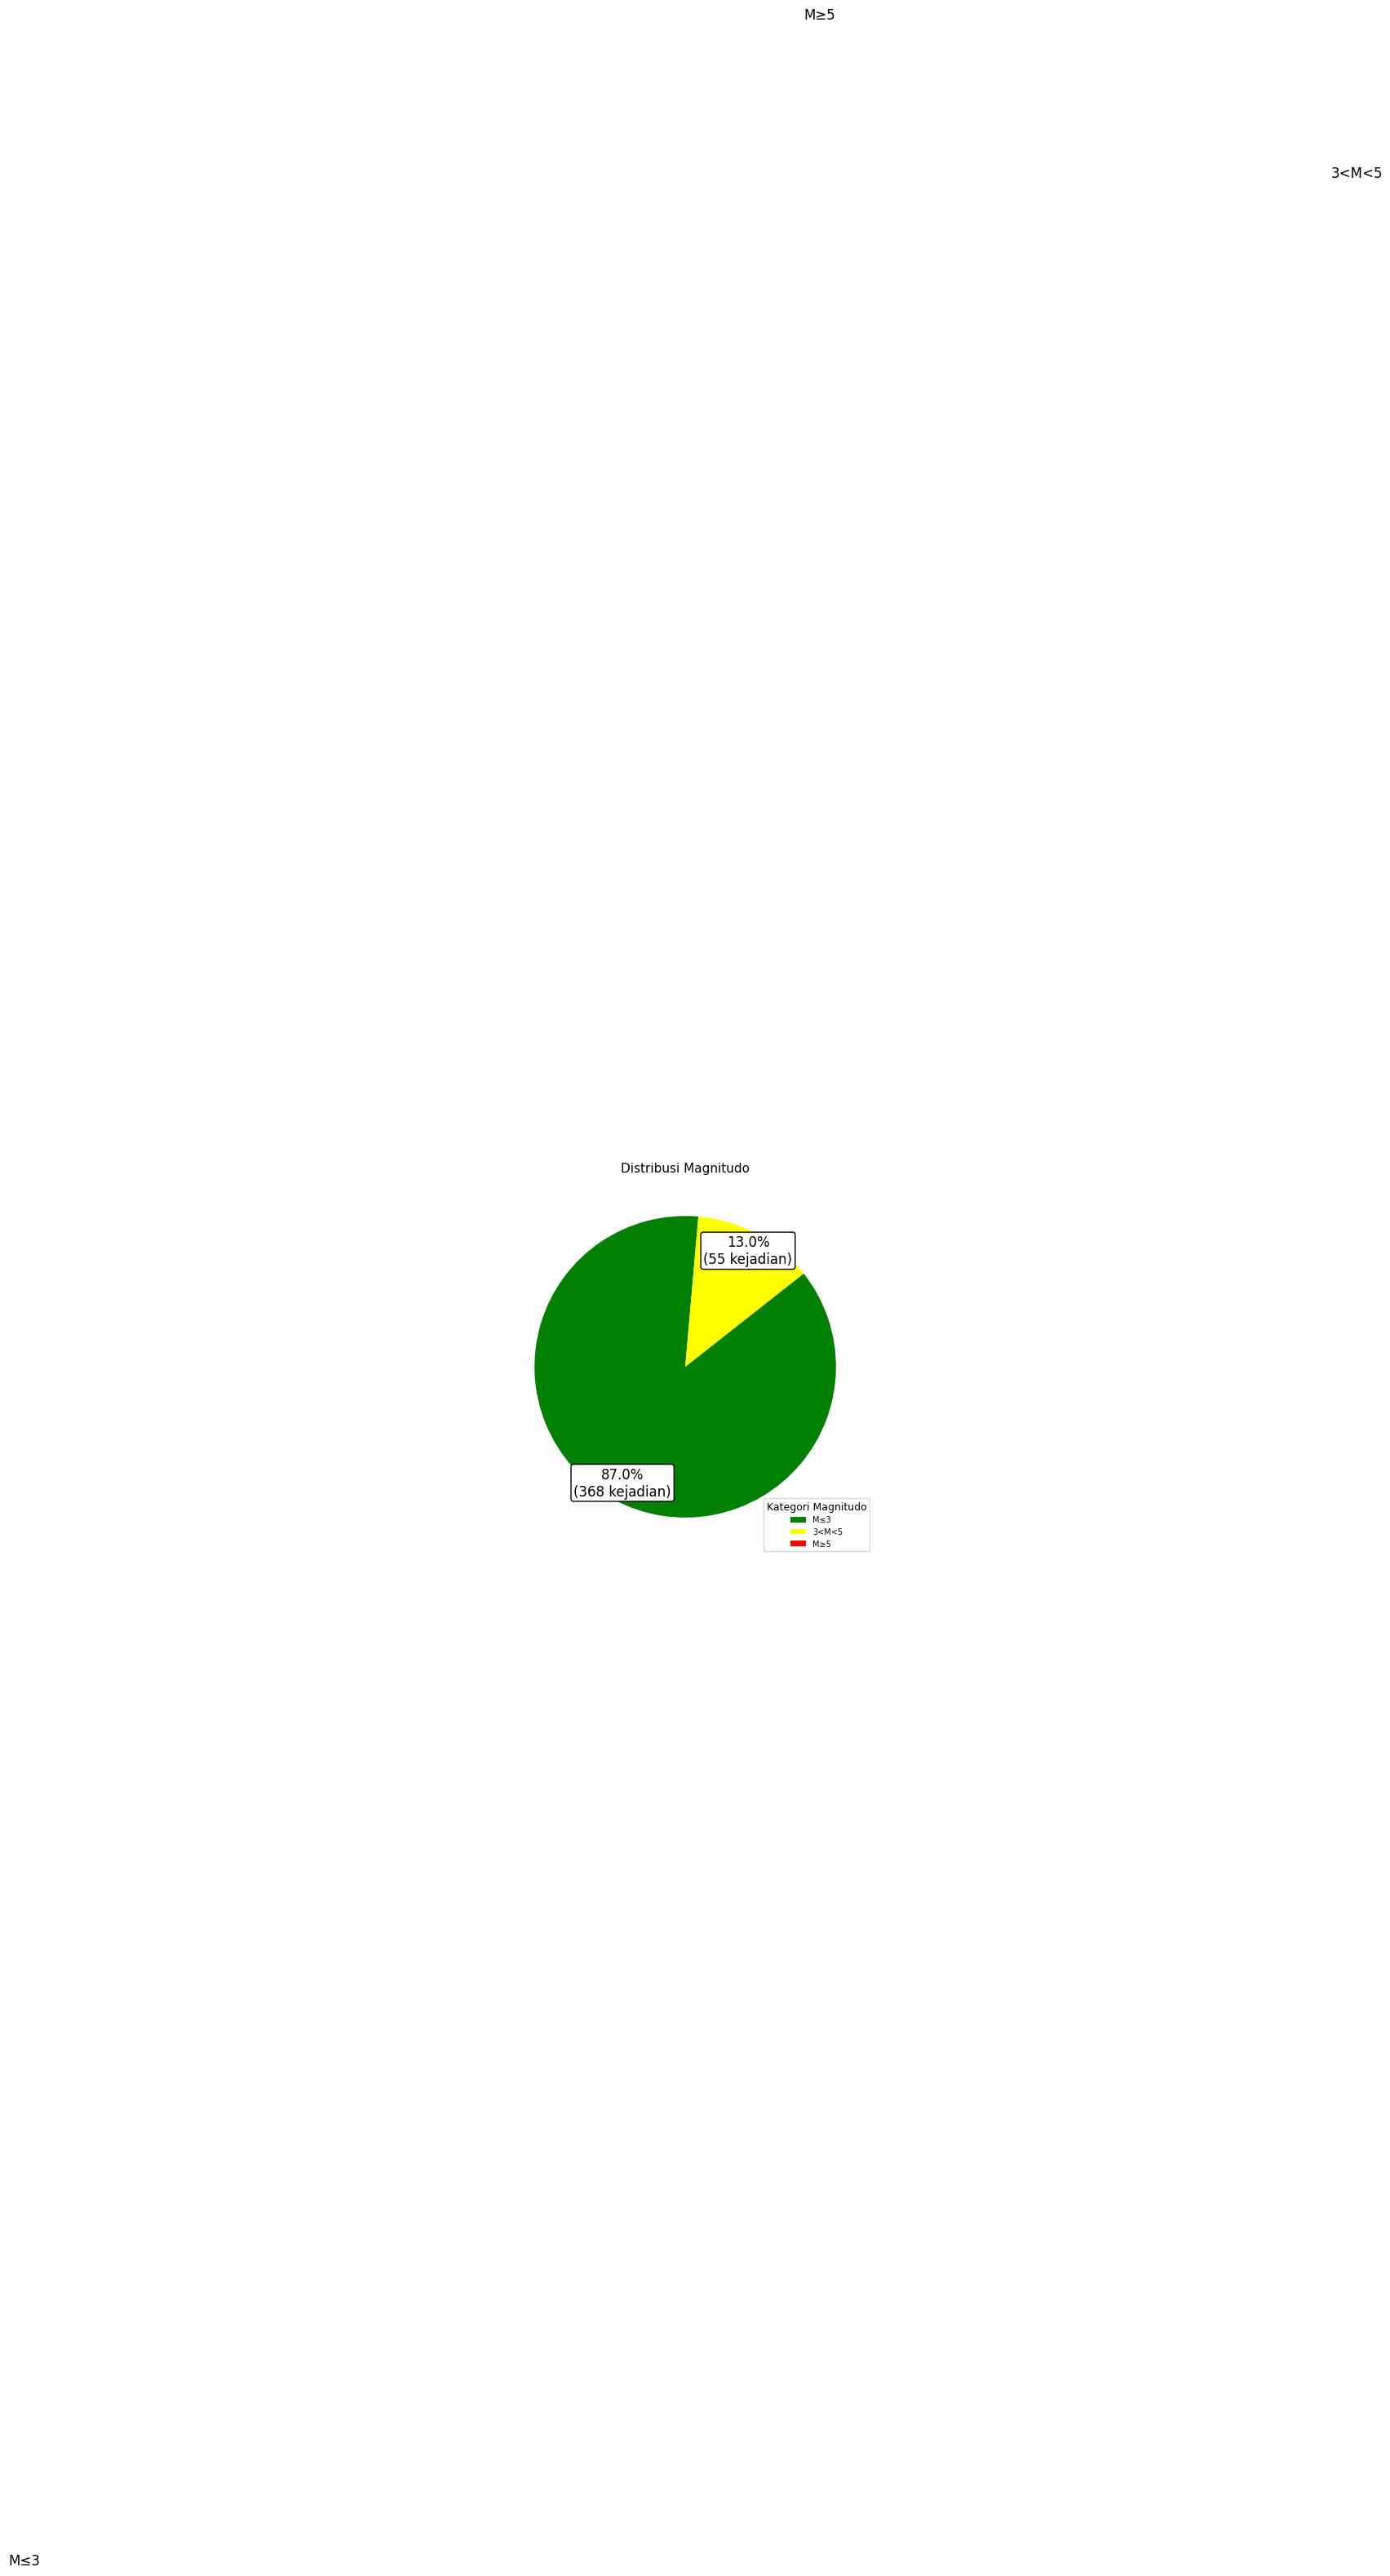

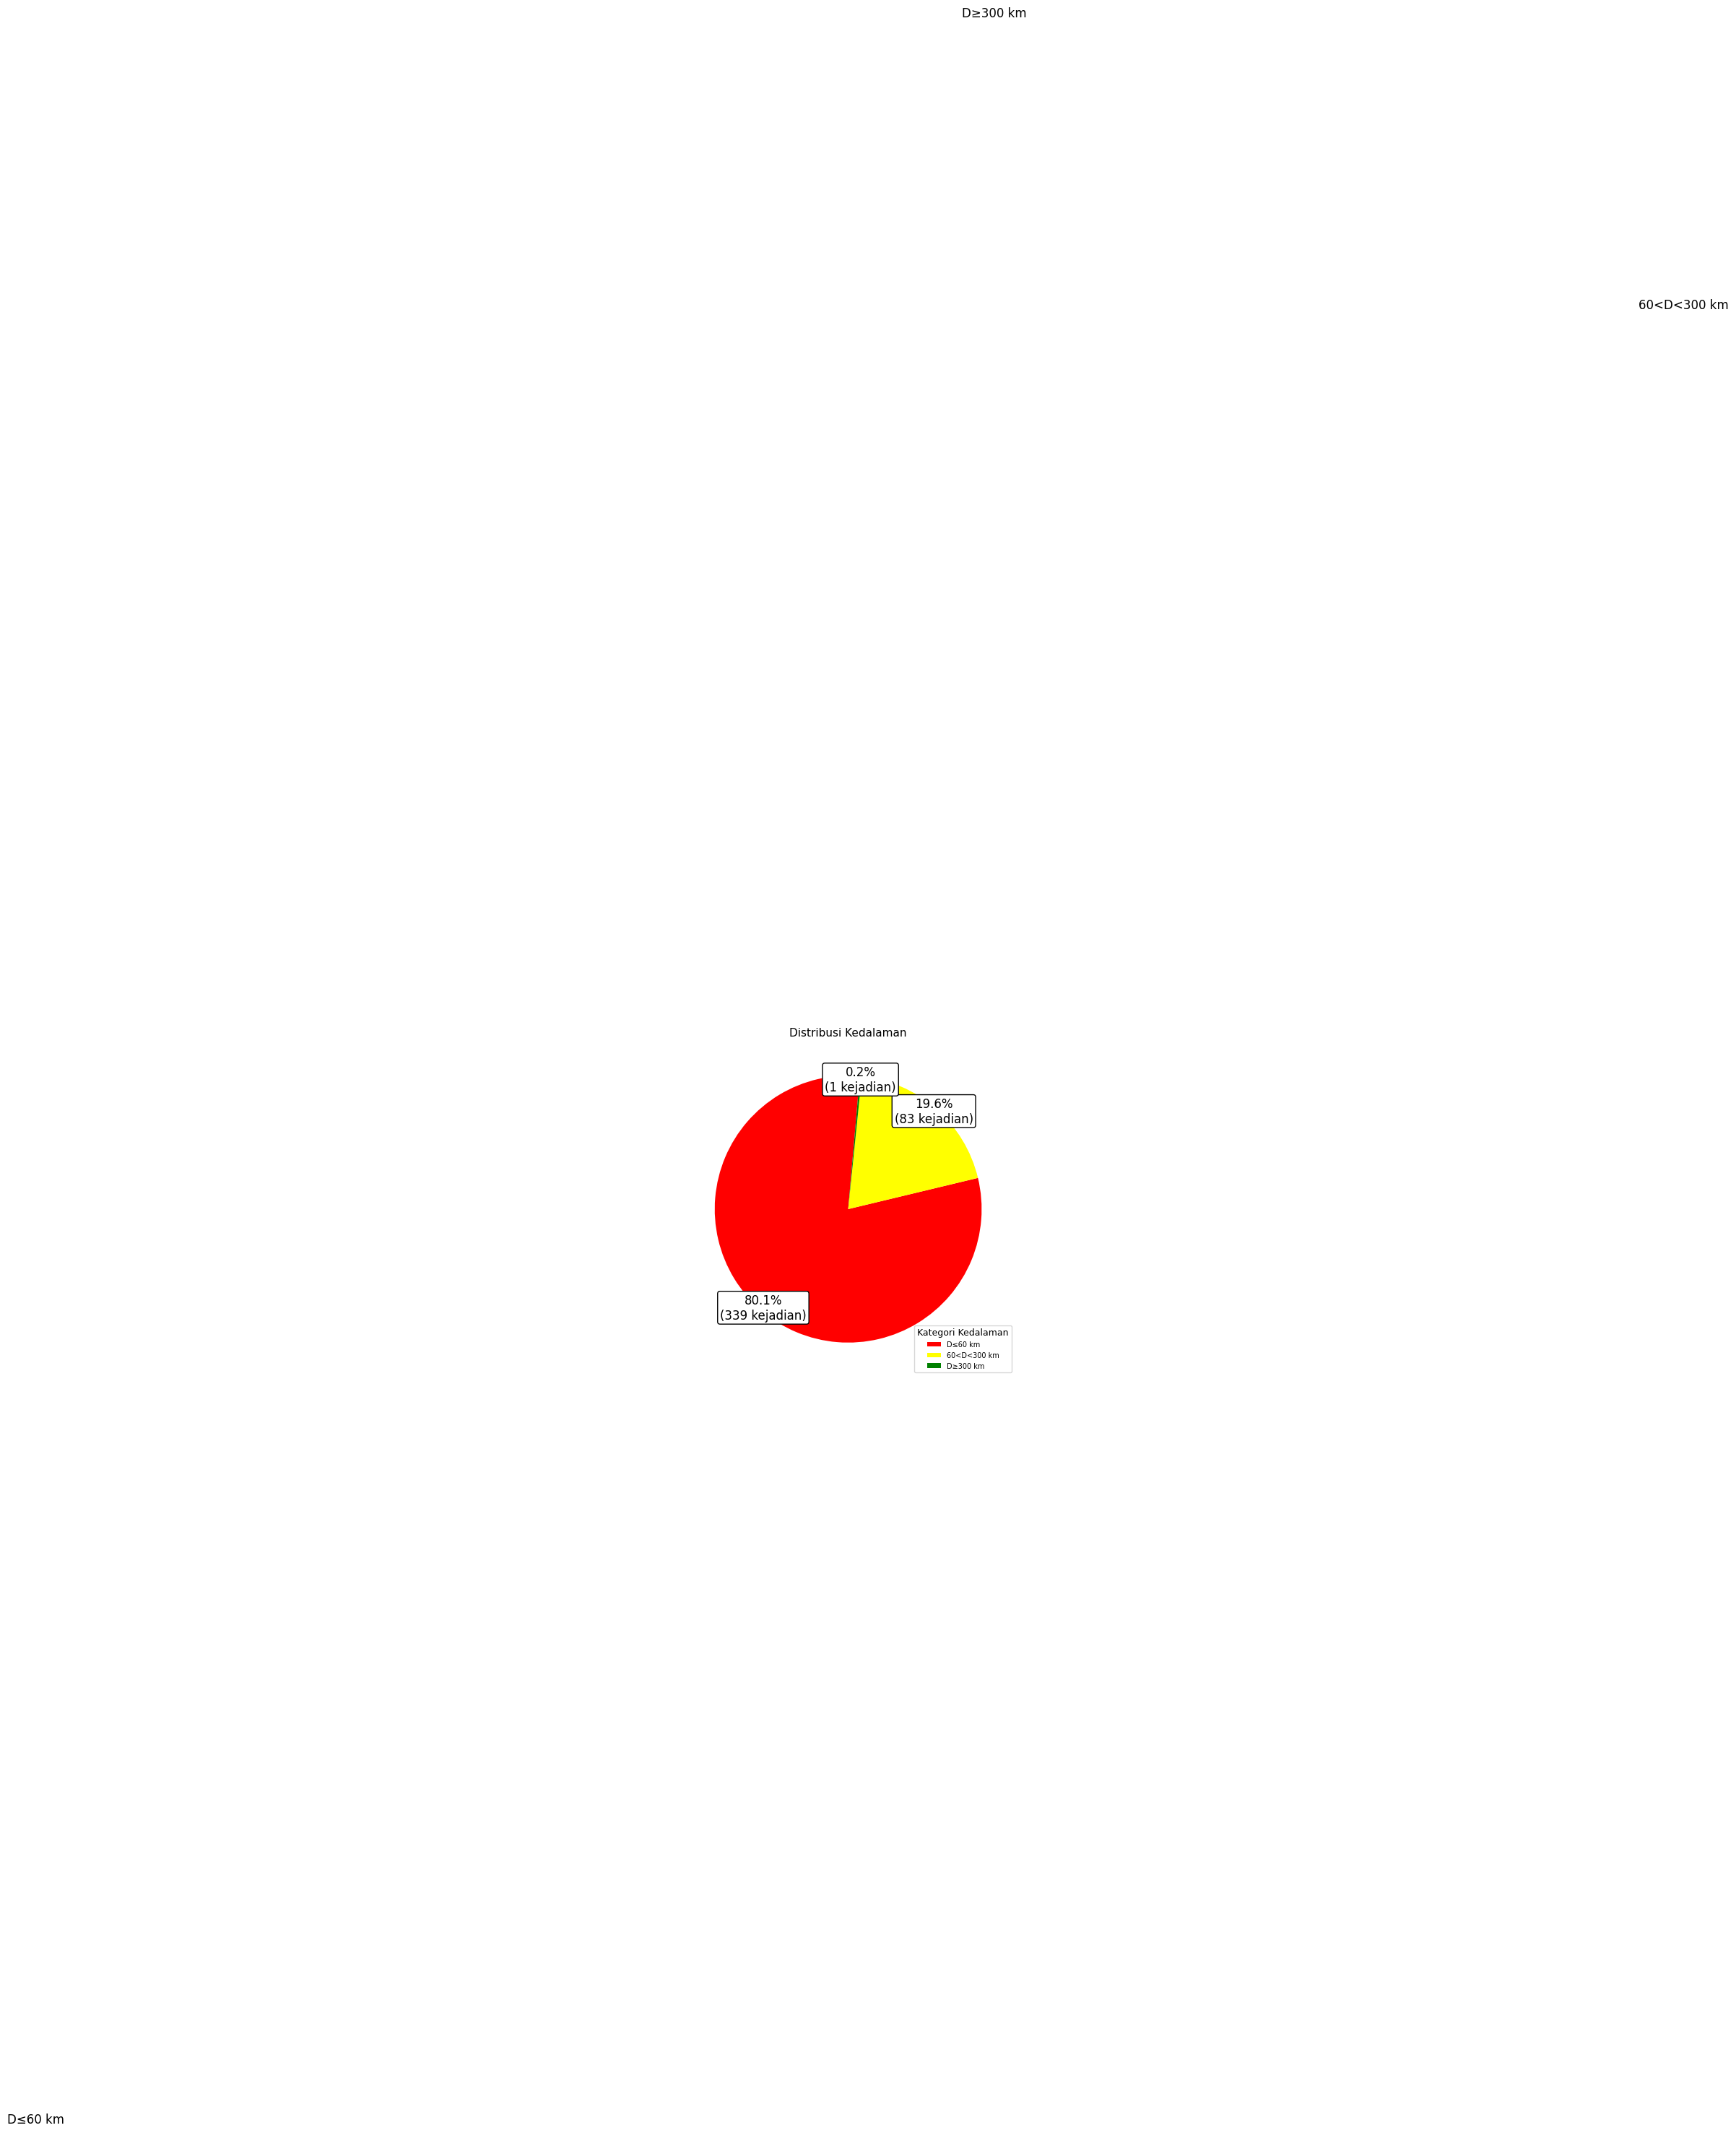

In [2]:
import numpy as np
import pygmt
import pandas as pd
import math
import matplotlib.pyplot as plt
import os
import tkinter as tk
import locale
from datetime import datetime, timedelta
from docx import Document
from docx.shared import Pt, Inches
from docx.shared import Cm
from docx.enum.text import WD_PARAGRAPH_ALIGNMENT
from docx.enum.table import WD_TABLE_ALIGNMENT
from docx.enum.section import WD_SECTION, WD_ORIENT
from geopy.distance import geodesic
from openpyxl import load_workbook
from tkcalendar import DateEntry 
from tkinter import ttk, filedialog, messagebox

selected_files=[]

def select_files():
    global selected_files
    selected_files = filedialog.askopenfilenames(title="Pilih File")
    if selected_files:
        messagebox.showinfo("File Terpilih", f"Jumlah file terpilih: {len(selected_files)}")

def process_data():
    global selected_files, tanggal_awal, tanggal_akhir, nama_folder
    CITY_FILE = "D:/Seismioto/Bahan/kabkota.txt"

    # Ambil tanggal awal & akhir dari GUI
    start_date_str = start_date_entry.get()
    end_date_str = end_date_entry.get()
    tanggal_awal = pd.to_datetime(start_date_str, format='%d/%m/%Y')
    tanggal_akhir = pd.to_datetime(end_date_str, format='%d/%m/%Y')

    if not selected_files:
        messagebox.showerror("Error", "Pilih file TXT terlebih dahulu!")
        return None, None

    combined_data = pd.DataFrame()

    def load_city_list():
        L = []
        if not os.path.exists(CITY_FILE):
            print("[WARN] kabkota.txt tidak ditemukan")
            return L
        with open(CITY_FILE, encoding="utf-8") as f:
            for line in f:
                line = line.strip()
                if not line or line.startswith("#"):
                    continue
                p = line.split(";")
                if len(p) < 3:
                    continue
                try:
                    lat = float(p[0])
                    lon = float(p[1])
                except Exception:
                    continue
                name = ";".join(p[2:])
                L.append((lat, lon, name))
        return L

    CITY_LIST = load_city_list()

    def calculate_azimuth(lat1, lon1, lat2, lon2):
        rlat1 = math.radians(lat1)
        rlon1 = math.radians(lon1)
        rlat2 = math.radians(lat2)
        rlon2 = math.radians(lon2)
        dlon = rlon2 - rlon1
        x = math.sin(dlon) * math.cos(rlat2)
        y = (math.cos(rlat1) * math.sin(rlat2) -
            math.sin(rlat1) * math.cos(rlat2) * math.cos(dlon))
        az = math.degrees(math.atan2(x, y))
        if az < 0:
            az += 360
        return az

    def azimuth_to_direction(a: float) -> str:
        if 0 <= a < 22.5 or 337.5 <= a < 360:
            return "Utara"
        if 22.5 <= a < 67.5:
            return "Timur Laut"
        if 67.5 <= a < 112.5:
            return "Timur"
        if 112.5 <= a < 157.5:
            return "Tenggara"
        if 157.5 <= a < 202.5:
            return "Selatan"
        if 202.5 <= a < 247.5:
            return "Barat Daya"
        if 247.5 <= a < 292.5:
            return "Barat"
        if 292.5 <= a < 337.5:
            return "Barat Laut"
        return "-"

    def nearest_city(lat, lon) -> str:
        if not CITY_LIST:
            return "-"
        try:
            lat = float(lat)
            lon = float(lon)
        except Exception:
            return "-"

        best_d = float("inf")
        best_city = "-"
        best_dir = "-"

        for clat, clon, cname in CITY_LIST:
            try:
                d = geodesic((lat, lon), (clat, clon)).km
            except Exception:
                continue
            if d < best_d:
                best_d = d
                best_city = cname
                az = calculate_azimuth(clat, clon, lat, lon)
                best_dir = azimuth_to_direction(az)

        if best_city == "-":
            return "-"

        jarak = int(round(best_d))
        arah = best_dir.replace(" ", "")  # TimurLaut, BaratDaya, dll
        return f"{jarak} km {arah} {best_city}"


    # ====== LOOP TIAP FILE TXT ======
    for file_path in selected_files:
        try:
            # Baca TXT pipe-separated, header di baris pertama
            df_txt = pd.read_csv(
                file_path,
                sep="|",
                dtype=str,        # baca dulu sebagai string untuk aman
                skip_blank_lines=True
            )

            # Pastikan kolom penting ada
            required_cols = ["Time", "Latitude", "Longitude", "Depth/km",
                             "Magnitude", "EventLocationName", "EventType", "Status"]
            missing = [c for c in required_cols if c not in df_txt.columns]
            if missing:
                messagebox.showerror(
                    "Error",
                    f"File {os.path.basename(file_path)} tidak memiliki kolom: {', '.join(missing)}"
                )
                continue

            # FILTER: hanya eventType = earthquake & status != other (kalau mau)
            mask_event = df_txt["EventType"].str.lower() == "earthquake"
            # Kalau mau pakai Status juga, misal yang confirmed/reviewed saja:
            mask_status = df_txt["Status"].str.lower().isin(["final"])
            df_txt = df_txt[mask_event & mask_status].copy()
            df_txt = df_txt[mask_event].copy()

            if df_txt.empty:
                continue

            # KONVERSI WAKTU: Time (UTC)
            def convert_utc_time(t_str):
                if pd.isna(t_str):
                    return None, None
                try:
                    t_utc = datetime.strptime(t_str, "%Y-%m-%dT%H:%M:%S")
                except ValueError:
                    try:
                        # jaga-jaga kalau ada fractional second
                        t_utc = datetime.strptime(t_str, "%Y-%m-%dT%H:%M:%S.%f")
                    except ValueError:
                        return None, None
                t_local = t_utc + timedelta(hours=0)
                return t_local.date(), t_local.strftime("%H:%M:%S")

            tanggal_list = []
            jam_list = []

            for t_str in df_txt["Time"]:
                tgl, jam = convert_utc_time(t_str)
                tanggal_list.append(tgl)
                jam_list.append(jam)

            df_txt["Tanggal"] = tanggal_list
            df_txt["Waktu (UTC)"] = jam_list

            # KONVERSI tipe numerik
            df_txt["Lintang"] = pd.to_numeric(df_txt["Latitude"], errors="coerce")
            df_txt["Bujur"] = pd.to_numeric(df_txt["Longitude"], errors="coerce")
            df_txt["Kedalaman"] = pd.to_numeric(df_txt["Depth/km"], errors="coerce")
            df_txt["Magnitude"] = pd.to_numeric(df_txt["Magnitude"], errors="coerce")
            mask_mag = df_txt["Magnitude"].notna() & (df_txt["Magnitude"] > 0)
            df_txt = df_txt[mask_mag].copy()

            if df_txt.empty:
                continue

            # Keterangan dari EventLocationName
            df_txt["Keterangan"] = df_txt["EventLocationName"].fillna("")

            # Diraskan default kosong
            df_txt["Dirasakan"] = ""

            # Bentuk DataFrame dengan kolom yang sama seperti dari XML
            parsed_data = df_txt[[
                "Tanggal",
                "Waktu (UTC)",
                "Lintang",
                "Bujur",
                "Kedalaman",
                "Magnitude",
                "Keterangan",
                "Dirasakan"
            ]].copy()

            # Round dan cast
            parsed_data["Tanggal"] = pd.to_datetime(parsed_data["Tanggal"], errors='coerce')
            parsed_data["Lintang"] = parsed_data["Lintang"].round(4)
            parsed_data["Bujur"] = parsed_data["Bujur"].round(4)
            # parsed_data["Kedalaman"] = parsed_data["Kedalaman"].round(0).astype("Int64")  # int tapi bisa NaN
            parsed_data["Kedalaman"] = parsed_data["Kedalaman"].round(1)
            parsed_data["Magnitude"] = parsed_data["Magnitude"].round(2)

            # FILTER tanggal & koordinat
            mask = (
                (parsed_data['Tanggal'] >= tanggal_awal) &
                (parsed_data['Tanggal'] <= tanggal_akhir)
            )

            filtered_data = parsed_data[mask].copy()
            # ===== INI YANG BARU - GANTI KETERANGAN =====
            print("Menghitung jarak kota terdekat...")
            filtered_data["Keterangan"] = filtered_data.apply(
                lambda row: nearest_city(row["Lintang"], row["Bujur"]), 
                axis=1
            )
            print("Selesai!")
            combined_data = pd.concat([combined_data, filtered_data], ignore_index=True)

        except Exception as e:
            messagebox.showerror("Error", f"Error parsing {file_path}: {str(e)}")
            continue

    if combined_data.empty:
        messagebox.showwarning("Warning", "Tidak ada data yang sesuai filter!")
        return
    
    # ===== FUNGSI: MERGE DENGAN DIRASAKAN =====
    def merge_with_dirasakan(combined_data, dirasakan_file, time_tolerance_seconds=5):
        """
        Merge data gempa dengan dirasakan.xlsx

        Aturan:
        1. Match berdasarkan tanggal + waktu (±5 detik)
        2. Jika match -> update kolom Dirasakan
        3. Jika tidak match -> tambahkan data dari Excel ke combined_data
        """

        import os
        import pandas as pd
        from tkinter import messagebox

        if not os.path.exists(dirasakan_file):
            messagebox.showerror(
                "Error",
                f"File '{dirasakan_file}' tidak ditemukan!"
            )
            return combined_data

        # ==========================
        # BACA FILE EXCEL
        # ==========================
        existing_data = pd.read_excel(dirasakan_file)

        # Pastikan kolom wajib ada
        required_columns = ['Tanggal', 'Waktu (UTC)']
        for col in required_columns:
            if col not in existing_data.columns:
                messagebox.showerror(
                    "Error",
                    f"Kolom '{col}' tidak ditemukan pada file dirasakan.xlsx"
                )
                return combined_data

        # ==========================
        # NORMALISASI TANGGAL & WAKTU
        # ==========================
        existing_data['Tanggal'] = pd.to_datetime(
            existing_data['Tanggal'],
            errors='coerce'
        )

        existing_data['Waktu (UTC)'] = (
            existing_data['Waktu (UTC)']
            .astype(str)
            .str.strip()
        )

        existing_data['Datetime'] = pd.to_datetime(
            existing_data['Tanggal'].astype(str)
            + ' '
            + existing_data['Waktu (UTC)'],
            errors='coerce'
        )

        combined_data['Tanggal'] = pd.to_datetime(
            combined_data['Tanggal'],
            errors='coerce'
        )

        combined_data['Waktu (UTC)'] = (
            combined_data['Waktu (UTC)']
            .astype(str)
            .str.strip()
        )

        combined_data['Datetime'] = pd.to_datetime(
            combined_data['Tanggal'].astype(str)
            + ' '
            + combined_data['Waktu (UTC)'],
            errors='coerce'
        )

        # ==========================
        # FLAG SEMENTARA
        # ==========================
        combined_data['from_excel'] = False

        indices_to_replace = []
        matched_existing = set()

        # ==========================
        # CARI DATA YANG MATCH
        # ==========================
        for idx_existing, row_existing in existing_data.iterrows():

            if pd.isna(row_existing['Datetime']):
                continue

            for idx_combined, row_combined in combined_data.iterrows():

                if pd.isna(row_combined['Datetime']):
                    continue

                if row_combined['from_excel']:
                    continue

                time_diff = abs(
                    (
                        row_combined['Datetime']
                        - row_existing['Datetime']
                    ).total_seconds()
                )

                if time_diff <= time_tolerance_seconds:

                    indices_to_replace.append(
                        (idx_combined, idx_existing)
                    )

                    matched_existing.add(idx_existing)

                    combined_data.loc[
                        idx_combined,
                        'from_excel'
                    ] = True

                    break

        # ==========================
        # UPDATE KOLOM DIRASAKAN
        # ==========================
        for idx_combined, idx_existing in indices_to_replace:

            if 'Dirasakan' in existing_data.columns:

                combined_data.loc[
                    idx_combined,
                    'Dirasakan'
                ] = existing_data.loc[
                    idx_existing,
                    'Dirasakan'
                ]

        # ==========================
        # TAMBAHKAN GEMPA YANG
        # TIDAK ADA DI COMBINED_DATA
        # ==========================
        rows_to_append = []

        for idx_existing, row_existing in existing_data.iterrows():

            if idx_existing in matched_existing:
                continue

            new_row = {}

            for col in combined_data.columns:

                if col in row_existing.index:
                    new_row[col] = row_existing[col]
                else:
                    new_row[col] = ''

            rows_to_append.append(new_row)

        if rows_to_append:

            combined_data = pd.concat(
                [
                    combined_data,
                    pd.DataFrame(rows_to_append)
                ],
                ignore_index=True
            )

        # ==========================
        # HAPUS KOLOM BANTU
        # ==========================
        columns_to_drop = []

        if 'from_excel' in combined_data.columns:
            columns_to_drop.append('from_excel')

        if 'Datetime' in combined_data.columns:
            columns_to_drop.append('Datetime')

        combined_data = combined_data.drop(
            columns=columns_to_drop,
            errors='ignore'
        )

        # ==========================
        # SORT BERDASARKAN WAKTU
        # ==========================
        combined_data['Datetime'] = pd.to_datetime(
            combined_data['Tanggal'].astype(str)
            + ' '
            + combined_data['Waktu (UTC)'].astype(str),
            errors='coerce'
        )

        combined_data = combined_data.sort_values(
            by='Datetime'
        ).reset_index(drop=True)

        combined_data = combined_data.drop(
            columns=['Datetime'],
            errors='ignore'
        )

        return combined_data
    
    # ===== FUNGSI: DEDUPLIKASI GEMPA =====
    def deduplicate_earthquakes(df, time_tolerance_seconds=5):
        """
        Menghapus gempa duplikat berdasarkan tanggal + waktu (±5 detik)
        Menyimpan data pertama (index terkecil) jika ada duplikat
        """
        if df.empty:
            return df

        df = df.sort_values(by=['Tanggal', 'Waktu (UTC)']).reset_index(drop=True)
        df['Datetime'] = pd.to_datetime(
            df['Tanggal'].astype(str) + ' ' + df['Waktu (UTC)'],
            errors='coerce'
        )

        duplicates_to_drop = []

        for i in range(len(df)):
            if i in duplicates_to_drop:
                continue

            current_time = df.loc[i, 'Datetime']
            current_date = df.loc[i, 'Tanggal']

            # Bandingkan dengan gempa berikutnya
            for j in range(i + 1, len(df)):
                if j in duplicates_to_drop:
                    continue

                compare_time = df.loc[j, 'Datetime']
                compare_date = df.loc[j, 'Tanggal']

                # Jika tanggal berbeda, skip
                if current_date != compare_date:
                    break

                # Cek perbedaan waktu
                time_diff = abs((current_time - compare_time).total_seconds())

                if time_diff <= time_tolerance_seconds:
                    # Tandai untuk dihapus (keep yang pertama)
                    duplicates_to_drop.append(j)

        # Hapus duplikat
        df_deduplicated = df.drop(duplicates_to_drop).reset_index(drop=True)
        df_deduplicated = df_deduplicated.drop(columns=['Datetime'])

        return df_deduplicated


    # ===== PROSES UTAMA =====

    # 1. Merge dengan dirasakan.xlsx
    existing_file = 'gempa_dirasakan_PGR3_UTC.xlsx'
    combined_data = merge_with_dirasakan(combined_data, existing_file, time_tolerance_seconds=5)
    
    # 2. Deduplikasi gempa
    # combined_data = deduplicate_earthquakes(combined_data, time_tolerance_seconds=5)

    # 3. Sort & format output
    combined_data['Tanggal'] = pd.to_datetime(combined_data['Tanggal'])
    combined_data['Datetime'] = pd.to_datetime(
        combined_data['Tanggal'].astype(str) + ' ' + combined_data['Waktu (UTC)'],
        errors='coerce'
    )
    combined_data = combined_data.sort_values(by='Datetime').reset_index(drop=True)
    combined_data = combined_data.drop(columns=['Datetime'])
    combined_data['Tanggal'] = combined_data['Tanggal'].dt.date

    # 4. Reorder columns & add No
    column_order = ['No', 'Tanggal', 'Waktu (UTC)', 'Lintang', 'Bujur', 'Magnitude', 'Kedalaman', 'Keterangan', 'Dirasakan']
    combined_data.insert(0, 'No', range(1, len(combined_data) + 1))
    combined_data = combined_data[column_order]

    # 5. Save output
    combined_data.to_csv('datalengkap_geodinamika.csv', index=False)

    # HAPUS yang lama, GANTI dengan ini:
    bulan_id = {
        1: "Januari", 2: "Februari", 3: "Maret", 4: "April",
        5: "Mei", 6: "Juni", 7: "Juli", 8: "Agustus",
        9: "September", 10: "Oktober", 11: "November", 12: "Desember"
    }

    if tanggal_awal.month == tanggal_akhir.month:
        nama_folder = f"Geodinamika {bulan_id[tanggal_awal.month]} {tanggal_awal.year}"
    else:
        nama_folder = f"Geodinamika {bulan_id[tanggal_awal.month]} - {bulan_id[tanggal_akhir.month]} {tanggal_akhir.year}"
        return nama_folder

    if not os.path.exists(nama_folder):
        os.makedirs(nama_folder)

    output_file = os.path.join(nama_folder, f'Data Gempabumi {nama_folder}.xlsx')
    combined_data.to_excel(output_file, index=False)

   # ===== TAMBAH SESUDAH PENYIMPANAN EXCEL, SEBELUM MESSAGEBOX =====
    data_peta_folder = os.path.join(nama_folder, "data peta")
    os.makedirs(data_peta_folder, exist_ok=True)

    # Klasifikasi berdasarkan kedalaman
    dangkal = combined_data[(combined_data['Kedalaman'] >= 0) & (combined_data['Kedalaman'] <= 60)].copy()
    menengah = combined_data[(combined_data['Kedalaman'] > 60) & (combined_data['Kedalaman'] < 300)].copy()
    dalam = combined_data[(combined_data['Kedalaman']>= 300)]
    # dalam_header = pd.DataFrame(columns=combined_data.columns)
    # dalam_header.to_csv(os.path.join(data_peta_folder, 'dalam.csv'), index=False)

    # Simpan file CSV
    if not dangkal.empty:
        dangkal.to_csv(os.path.join(data_peta_folder, 'dangkal.csv'), index=False)
    if not menengah.empty:
        menengah.to_csv(os.path.join(data_peta_folder, 'menengah.csv'), index=False)
    if not dalam.empty:
        dalam.to_csv(os.path.join(data_peta_folder, 'dalam.csv'), index=False)

    # messagebox.showinfo("Proses", f"Data berhasil diproses dan disimpan ke:\n1. {output_file}\n2. datalengkap_geodinamika.csv di direktori script.")
    return nama_folder

def print_analysis():
    global nama_folder
    def read_csv_and_analyze(tanggal_awal, tanggal_akhir):
        
        # Step 1: Read CSV file
        file_path = "datalengkap_geodinamika.csv"
        data = pd.read_csv(file_path)
        
        # Konversi kolom Tanggal ke datetime dan ambil hanya tanggalnya
        data['Tanggal'] = pd.to_datetime(data['Tanggal']).dt.date
        tanggal_awal = pd.to_datetime(tanggal_awal).date()
        tanggal_akhir = pd.to_datetime(tanggal_akhir).date()
          
        # Filter data berdasarkan tanggal yang dipilih
        data = data[(data['Tanggal'] >= tanggal_awal) & (data['Tanggal'] <= tanggal_akhir)]

        # Drop the 'Magnitude Category' and 'Depth Category' columns
        output_data = data.drop(columns=['Magnitude Category', 'Depth Category'], errors='ignore')

        # Create magnitude and depth categories
        categories_magnitude = ['M≤3', '3<M<5', 'M≥5']
        data['Magnitude'] = pd.to_numeric(data['Magnitude'], errors='coerce')
        data['Magnitude Category'] = pd.cut(data['Magnitude'], bins=[0, 3, 5, float('inf')], labels=categories_magnitude, right=True)

        categories_depth = ['D≤60 km', '60<D<300 km', 'D≥300 km']
        data['Kedalaman'] = pd.to_numeric(data['Kedalaman'], errors='coerce')
        data['Depth Category'] = pd.cut(data['Kedalaman'], bins=[0, 60, 300, float('inf')], labels=categories_depth, right=True)       
        
        # Group data by day and categories for analysis
        # magnitude_summary = (data.groupby([data['Tanggal'], 'Magnitude Category']).size().unstack(fill_value=0).reindex(index=all_dates, fill_value=0).reindex(columns=categories_magnitude, fill_value=0))
        # depth_summary = (data.groupby([data['Tanggal'], 'Depth Category']).size().unstack(fill_value=0).reindex(index=all_dates, fill_value=0).reindex(columns=categories_depth, fill_value=0))
        
        magnitude_summary = (data.groupby([data['Tanggal'], 'Magnitude Category'])
                            .size()
                            .unstack(fill_value=0)
                            .reindex(index=(pd.date_range(start=tanggal_awal, end=tanggal_akhir, freq='D')), fill_value=0)
                            .reindex(columns=categories_magnitude, fill_value=0))

        depth_summary = (data.groupby([data['Tanggal'], 'Depth Category'])
                        .size()
                        .unstack(fill_value=0)
                        .reindex(index=(pd.date_range(start=tanggal_awal, end=tanggal_akhir, freq='D')), fill_value=0)
                        .reindex(columns=categories_depth, fill_value=0))

        # Add totals row and columns for 'Gempa Dirasakan' and 'Gempa Merusak'
        magnitude_summary['Jumlah Total'] = magnitude_summary.sum(axis=1)
        magnitude_summary['Gempa Dirasakan'] = 0
        magnitude_summary['Gempa Merusak'] = 0
        magnitude_summary.loc['Jumlah Gempa'] = magnitude_summary.sum()

        depth_summary['Jumlah Total'] = depth_summary.sum(axis=1)
        depth_summary['Gempa Dirasakan'] = 0
        depth_summary['Gempa Merusak'] = 0
        depth_summary.loc['Jumlah Gempa'] = depth_summary.sum()

        # Mengisi kolom 'Gempa Dirasakan' jika kolom 'Dirasakan' terisi
        for index, row in data.iterrows():
            if pd.notna(row['Dirasakan']) and row['Dirasakan'].strip() != '':
                if row['Tanggal'] in magnitude_summary.index:
                    magnitude_summary.at[row['Tanggal'], 'Gempa Dirasakan'] += 1
                if row['Tanggal'] in depth_summary.index:
                    depth_summary.at[row['Tanggal'], 'Gempa Dirasakan'] += 1

        magnitude_summary.at['Jumlah Gempa', 'Gempa Dirasakan'] = magnitude_summary['Gempa Dirasakan'].sum()
        depth_summary.at['Jumlah Gempa', 'Gempa Dirasakan'] = depth_summary['Gempa Dirasakan'].sum()

        # Untuk menangani row 'Jumlah Gempa' yang bukan tanggal
        magnitude_summary.index = [x.strftime('%Y-%m-%d') if isinstance(x, pd.Timestamp) else x for x in magnitude_summary.index]
        depth_summary.index = [x.strftime('%Y-%m-%d') if isinstance(x, pd.Timestamp) else x for x in depth_summary.index]

        # Save the analysis to Excel
        output_file = os.path.join(nama_folder, f'Analisis Gempabumi {nama_folder}.xlsx')
        with pd.ExcelWriter(output_file, engine='xlsxwriter') as writer:
            output_data.to_excel(writer, sheet_name='Earthquake Data', index=False)
            magnitude_summary.to_excel(writer, sheet_name='Magnitude Summary')
            depth_summary.to_excel(writer, sheet_name='Depth Summary')
            plot_charts(magnitude_summary, depth_summary, writer, nama_folder, tanggal_awal, tanggal_akhir)

        # Autofit columns
        autofit_columns(output_file, 'Earthquake Data')
        autofit_columns(output_file, 'Magnitude Summary')
        autofit_columns(output_file, 'Depth Summary')

        #messagebox.showinfo("Info", f"Analisis berhasil disimpan di:\n{output_file}")

    def plot_charts(magnitude_summary, depth_summary, writer, nama_folder, tanggal_awal, tanggal_akhir,):

        # ================== MAGNITUDE BAR CHART ==================
        categories = ['M≤3', '3<M<5', 'M≥5']
        colors = ['green', 'yellow', 'red']
        
        # Remove total row
        magnitude_summary_without_total = magnitude_summary.drop(index='Jumlah Gempa', errors='ignore')
        
        # Reindex with all dates and fill missing with 0
        magnitude_summary_without_total.index = pd.to_datetime(magnitude_summary_without_total.index)
        magnitude_summary_without_total.index = magnitude_summary_without_total.index.strftime('%d-%m-%Y')

        # Plot setup
        fig, ax = plt.subplots(figsize=(10, 6))
        bar_width = 0.25
        x = np.arange(len(magnitude_summary_without_total.index))

        # Plot each category
        for i, category in enumerate(categories):
            ax.bar(x + i * bar_width, 
                magnitude_summary_without_total[category], 
                bar_width, 
                label=category, 
                color=colors[i], 
                edgecolor='black')

        # Chart formatting
        ax.set_title('Frekuensi Gempa Berdasarkan Magnitudo',fontsize=14, pad=20)
        ax.set_xlabel('Tanggal', fontsize=12)
        ax.set_ylabel('Jumlah Kejadian', fontsize=12)
        
        # Set x-ticks to show all dates
        ax.set_xticks(x + bar_width)
        
        # Update x-tick labels dengan format baru
        date_labels = [idx.strftime('%d %b') if hasattr(idx, 'strftime') else str(idx)[:5] 
               for idx in magnitude_summary_without_total.index]
        ax.set_xticklabels(date_labels, rotation=30, ha='right', fontsize=8)    
        
        ax.legend(title='Kategori Magnitudo', fontsize=10)
        ax.grid(axis='y', linestyle='--', alpha=0.7)

        # Add value labels
        for p in ax.patches:
            height = p.get_height()
            if height > 0:  # Hanya tampilkan label jika nilai > 0
                ax.annotate(f'{int(height)}', 
                        (p.get_x() + p.get_width() / 2, height),
                        ha='center', va='bottom', fontsize=8)

        plt.tight_layout()
        plt.savefig(os.path.join(nama_folder, 'diagbat_mag.png'), dpi=300)
        plt.close()

        # Insert to Excel
        worksheet_mag = writer.sheets['Magnitude Summary']
        worksheet_mag.insert_image('I2', os.path.join(nama_folder, 'diagbat_mag.png'), 
                                {'x_scale': 0.5, 'y_scale': 0.5})

        # Buat diagram lingkaran magnitude
        magnitude_total = magnitude_summary.loc['Jumlah Gempa', ['M≤3', '3<M<5', 'M≥5']]
        labels = ['M≤3', '3<M<5', 'M≥5']
        colors = ['green', 'yellow', 'red']

        # Membuat figure dan pie chart
        fig, ax = plt.subplots(figsize=(6, 6))

        # Fungsi untuk menampilkan persentase dan jumlah kejadian di setiap segmen
        def func(pct, allvals):
            absolute = int(np.round(pct/100.*np.sum(allvals)))
            if absolute > 0:
                return f'{pct:.1f}%\n({absolute} kejadian)'
            else:
                return ''  # Jika tidak ada kejadian, label tidak ditampilkan

        # Membuat pie chart
        wedges, texts, autotexts = ax.pie(
            magnitude_total,
            labels=labels,
            colors=colors,
            startangle=85,
            autopct=lambda pct: func(pct, magnitude_total),  # Menampilkan persentase dan jumlah kejadian
            pctdistance=0.875,  # Jarak persentase dari pusat pie
            labeldistance=9  # Jarak label dari pusat pie (aslinya 1.17)
        )

        # Mengatur ukuran font dan latar belakang putih untuk label dan persentase
        for text in texts:
            text.set_fontsize(12)
            text.set_bbox(dict(facecolor='white', edgecolor='none', boxstyle='round,pad=0.2'))

        for autotext in autotexts:
            autotext.set_fontsize(12)
            autotext.set_bbox(dict(facecolor='white', edgecolor='black', boxstyle='round,pad=0.2'))

        plt.title('Distribusi Magnitudo', fontsize=11)
        ax.legend(title='Kategori Magnitudo', fontsize=7, title_fontsize='9', loc='lower right')
        plt.tight_layout()

        plt.savefig(os.path.join(nama_folder, 'diaglingk_mag.png'))

        # Insert the magnitude pie chart into Excel
        worksheet_mag.insert_image('P2', os.path.join(nama_folder, 'diaglingk_mag.png'), {'x_scale': 0.5, 'y_scale': 0.5})
        
        # ================== DEPTH BAR CHART ==================
        categories_depth = ['D≤60 km', '60<D<300 km', 'D≥300 km']
        colors_depth = ['red', 'yellow', 'green']
        
       # Remove total row
        depth_summary_without_total = depth_summary.drop(index='Jumlah Gempa', errors='ignore')
        
        # Reindex with all dates and fill missing with 0
        depth_summary_without_total.index = pd.to_datetime(depth_summary_without_total.index)
        depth_summary_without_total.index = depth_summary_without_total.index.strftime('%d-%m-%Y')

        # Plot setup
        fig, ax = plt.subplots(figsize=(10, 6))
        bar_width = 0.25
        x = np.arange(len(depth_summary_without_total.index))
        
        # Plot each category
        for i, category in enumerate(categories_depth):
            ax.bar(x + i * bar_width, 
                depth_summary_without_total[category], 
                bar_width, 
                label=category, 
                color=colors_depth[i], 
                edgecolor='black')

        # Chart formatting
        ax.set_title('Frekuensi Gempa Berdasarkan Kedalaman' ,fontsize=14, pad=20)
        ax.set_xlabel('Tanggal', fontsize=12)
        ax.set_ylabel('Jumlah Kejadian', fontsize=12)
        
        # Set x-ticks to show all dates
        ax.set_xticks(x + bar_width)
        
        # Update x-tick labels dengan format baru
        date_labels = [idx.strftime('%d %b') if hasattr(idx, 'strftime') else str(idx)[:5] 
               for idx in depth_summary_without_total.index]
        ax.set_xticklabels(date_labels, rotation=30, ha='right', fontsize=8)  
        
        ax.legend(title='Kategori Kedalaman', fontsize=10)
        ax.grid(axis='y', linestyle='--', alpha=0.7)

        for p in ax.patches:
            height = p.get_height()
            if height > 0:  # Hanya tampilkan label jika nilai > 0
                ax.annotate(f'{int(height)}', 
                        (p.get_x() + p.get_width() / 2, height),
                        ha='center', va='bottom', fontsize=8)

        plt.tight_layout()
        plt.savefig(os.path.join(nama_folder, 'diagbat_depth.png'), dpi=300)
        plt.close()

        worksheet_depth = writer.sheets['Depth Summary']
        worksheet_depth.insert_image('I2', os.path.join(nama_folder, 'diagbat_depth.png'), 
                                {'x_scale': 0.5, 'y_scale': 0.5})

        # buat digram lingkaran depth
        depth_total = depth_summary.loc['Jumlah Gempa', ['D≤60 km', '60<D<300 km', 'D≥300 km']]
        labels = ['D≤60 km', '60<D<300 km', 'D≥300 km']
        colors = ['red', 'yellow', 'green']
        
        # Membuat figure dan pie chart
        fig, ax = plt.subplots(figsize=(6, 6))
        
        # Fungsi untuk menampilkan persentase dan jumlah kejadian di setiap segmen
        def func(pct, allvals):
            absolute = int(np.round(pct/100.*np.sum(allvals)))
            if absolute > 0:
                return f'{pct:.1f}%\n({absolute} kejadian)'
            else:
                return ''  # Jika tidak ada kejadian, label tidak ditampilkan
                  
        # Membuat pie chart
        wedges, texts, autotexts = ax.pie(
            depth_total,
            labels=labels,
            colors=colors,
            startangle=85,
            autopct=lambda pct: func(pct, magnitude_total),  # Menampilkan persentase dan jumlah kejadian
            pctdistance=0.975,  # Jarak persentase dari pusat pie
            labeldistance=9  # Jarak label dari pusat pie (aslinya 1.15)
        )

        # Mengatur ukuran font dan latar belakang putih untuk label dan persentase
        for text in texts:
            text.set_fontsize(12)
            text.set_bbox(dict(facecolor='white', edgecolor='none', boxstyle='round,pad=0.2'))

        for autotext in autotexts:
            autotext.set_fontsize(12)
            autotext.set_bbox(dict(facecolor='white', edgecolor='black', boxstyle='round,pad=0.2'))

        plt.title('Distribusi Kedalaman', fontsize=11)
        ax.legend(title='Kategori Kedalaman', fontsize=7, title_fontsize='9', loc='lower right')
        plt.tight_layout()
        plt.savefig(os.path.join(nama_folder, 'diaglingk_depth.png'))

        # Insert the magnitude pie chart into Excel
        worksheet_depth.insert_image('P2', os.path.join(nama_folder, 'diaglingk_depth.png'), {'x_scale': 0.5, 'y_scale': 0.5})   
    
    def autofit_columns(file_path, sheet_name):
        """
        Menyesuaikan lebar kolom di Excel berdasarkan panjang konten.
        """
        workbook = load_workbook(file_path)  # Membuka workbook yang telah disimpan
        worksheet = workbook[sheet_name]  # Mendapatkan worksheet berdasarkan nama sheet

        for col in worksheet.columns:
            max_length = 0
            column = col[0].column_letter  # Mendapatkan huruf kolom, misalnya 'A', 'B', dst.
            for cell in col:
                try:
                    # Mencari panjang maksimum dari setiap kolom
                    if len(str(cell.value)) > max_length:
                        max_length = len(str(cell.value))
                except:
                    pass
            adjusted_width = (max_length + 2)  # Menambah padding
            worksheet.column_dimensions[column].width = adjusted_width  # Mengatur lebar kolom

        workbook.save(file_path)  # Menyimpan workbook setelah penyesuaian
        workbook.close()  # Menutup workbook untuk memastikan semua perubahan disimpan
    
    # Panggil fungsi utama dengan tanggal yang dipilih
    read_csv_and_analyze(tanggal_awal, tanggal_akhir)

def print_map():
   #membuat file .dat
    input="datalengkap_geodinamika.csv"
    df = pd.read_csv(input)
    global nama_folder

    # Memilih kolom yang diinginkan
    selected_columns = df[['Bujur','Lintang','Kedalaman', 'Magnitude']]

    # Menulis data ke file DAT
    with open('inputpeta.dat', 'w') as file:
        for index, row in selected_columns.iterrows():
            line = '  '.join(row.astype(str))  # Menggabungkan semua elemen baris menjadi satu string dengan spasi sebagai pemisah
            file.write(line + '\n')
            
    # Membaca data dari hasil2.csv
    data = pd.read_csv(input)

    # Buat figure
    fig = pygmt.Figure()

    # Buat color palette untuk kedalaman gempa
    pygmt.makecpt(cmap="geo", series=[-7000, 4000])
    pygmt.makecpt(cmap="red,yellow,green", series="0,60,300,1000", output="quakes.cpt")

    #title_text = f"Peta Seismisitas Wilayah Bali dan Sekitarnya \nPeriode {start_date_formatted} hingga {end_date_formatted}"
    data['Magnitude'] = pd.to_numeric(data['Magnitude'], errors='coerce')  # Ganti nilai tidak valid dengan NaN

    # Menambahkan peta dasar dengan grid dan garis pantai
    fig.grdimage(
        grid="D:/Seismioto/Bahan/earth_relief_15s.grd",
        region=[113.7, 120, -13.7, -6.6],
        projection="M17c",
        #shading=True,
        frame=["xa2g2", "ya2g2"])#'+t"Peta Seismisitas"'])

  
    #fig.plot(data="D:/Seismioto/Bahan/floresthrust.gmt", pen="2,black")
    fig.plot(data="D:/Seismioto/Bahan/sesar2.gmt", pen="1.5,black",fill='black')
    fig.plot(data="D:/Seismioto/Bahan/sesar3.gmt", pen="1.5,black")
    
    # Plot gempa yang tidak dirasakan (kolom 'Dirasakan' kosong)
    gempa_tidak_dirasakan = data[data['Dirasakan'].isna()]
    if not gempa_tidak_dirasakan.empty:
        fig.plot(
            x=gempa_tidak_dirasakan['Bujur'],
            y=gempa_tidak_dirasakan['Lintang'],
            size=0.08*gempa_tidak_dirasakan['Magnitude'],
            style="cc",  # Lingkaran
            fill=gempa_tidak_dirasakan['Kedalaman'].astype(float),  # Warna berdasarkan kedalaman
            cmap="quakes.cpt",  # Gunakan colormap yang telah ditentukan
            pen="black"
        )
    else:
        print("ada gempa bumi yang dirasakan untuk diplot.")

    # Plot gempa yang dirasakan (kolom 'Dirasakan' terisi)
    gempa_dirasakan = data[~data['Dirasakan'].isna()]
    if not gempa_dirasakan.empty:
        fig.plot(
            x=gempa_dirasakan['Bujur'],
            y=gempa_dirasakan['Lintang'],
            size=0.1*gempa_dirasakan['Magnitude'],
            style="a0.5c",  # Simbol bintang
            fill="orange",  # Warna bintang merah
            pen="1p,black"  # Garis tepi hitam dengan ketebalan 1 point
        )
    else:
        print("tidak ada gempa bumi yang dirasakan untuk diplot.")
  
# Menambahkan Keterangan
    fig.image('D:/Seismioto/Bahan/LogoBMKG.png', position='n1.12/0.85+w1.1i')
    fig.image('D:/Seismioto/Bahan/mtangn.png', position='n1.1/0.69+w1.1i')
    fig.basemap(map_scale="n1.18/0.64+w200k+f0.1p+lKm")
    with fig.inset(position="n1.03/0.25+w5c/2.5c", box="+pblack"):
        fig.coast(
            region=[97, 140, -15, 7],
            shorelines='0.5p,black',
            projection="M5c",
            land="green",
            water="lightblue"
        )
        fig.plot(x=[117.31, 113.21, 113.21, 117.31, 117.31], y=[-7, -7, -12, -12, -7], pen="1p,red")
    fig.legend(spec="D:/Seismioto/Bahan/legenda.gmt", position="n1.03/0.0+w5c",box="+gwhite+p1p,black")

        # Membuat cross section
    fig.plot(x=[115.8, 116.2], y=[-11.5, -7.5], projection="M", pen=2)
    fig.text(x=115.8, y=-11.6, text="A", font="12,Helvetica")
    fig.text(x=116.2, y=-7.4, text="A1", font="12,Helvetica")
    pygmt.project(
        data="inputpeta.dat",
        unit=True,
        center=[115.8, -11.5],
        endpoint=[116.2, -7.5],
        width=[-400, 400],
        convention="pz",
        outfile="crsx.dat"
    )

    fig.shift_origin(yshift=8, xshift=17.5)
    fig.plot(
        x=[112, 112, 115.55, 115.55],  # Koordinat X dari sudut-sudut persegi
        y=[-12.6, -13.95, -13.95, -12.6],  # Koordinat Y dari sudut-sudut persegi
        fill="white",  # Warna latar belakang
        close=True  # Menutup jalur untuk membuat persegi berisi warna 
    )

    pygmt.config(FONT_LABEL="8p")

    # Buat peta cross section dengan basemap
    fig.basemap(
        projection="X5c/-3c",
        region=[0, 500, 0, 800],
        frame=['xafg+lJarak (km)+f2p', 'yafg+lKedalaman (km)+f2p', "wsEN"]
    )

        # Membuat garis cross section   
    cross = pd.read_csv('crsx.dat', delimiter='\s+', header=None)
    # Define your column names
    header = ['Distance', 'Dept', 'Mag']

    # Assign the header
    cross.columns = header

    fig.plot(x=cross.Distance, 
                y=cross.Dept, 
                projection="X5/-3", 
                size =0.035 * (2 * cross.Mag), style="cc", 
                fill = cross.Dept, 
                cmap = "quakes.cpt", 
                pen = 'black'),
                #region = region_cs)
    fig.text(x=20, y=35, text="A", font="9,Helvetica")
    fig.text(x=480, y=35, text="A1", font="9,Helvetica")

    output_map_filename = os.path.join(nama_folder, f'Peta Seismisitas {nama_folder}.png')
    # Menyimpan gambar
    fig.savefig(fname=output_map_filename)
    #fig.show()
    
    #messagebox.showinfo("Cetak Peta", "Peta Berhasil di Cetak")
    return nama_folder

def sekali_jalan():
    process_data()
    print_analysis()
    print_map()
    messagebox.showinfo("Seismioto", "Well done mate")

# Membuat jendela utama
root = tk.Tk()
root.title("Seismioto")
root.geometry("500x400")

# Tombol untuk memilih file
select_file_button = ttk.Button(root, text="Pilih File", command=select_files)
select_file_button.pack(pady=10)

# Pilihan tanggal awal dan akhir
ttk.Label(root, text="Pilih Tanggal Awal:").pack(pady=5)
start_date_entry = DateEntry(root, width=12, background='darkblue', foreground='white', borderwidth=2, date_pattern='dd/mm/yyyy')
start_date_entry.pack(pady=5)

ttk.Label(root, text="Pilih Tanggal Akhir:").pack(pady=5)
end_date_entry = DateEntry(root, width=12, background='darkblue', foreground='white', borderwidth=2, date_pattern='dd/mm/yyyy')
end_date_entry.pack(pady=5)

# Tombol cetak laporan Word
print_report_button = ttk.Button(root, text="Loz Gandoz", command=sekali_jalan)
print_report_button.pack(pady=5)

# Tombol proses
process_button = ttk.Button(root, text="Proses", command=process_data)
process_button.pack(pady=10)

# Tombol cetak analisis xlsx
print_analysis_button = ttk.Button(root, text="Cetak Analisis xlsx", command=print_analysis)
print_analysis_button.pack(pady=5)

# Tombol cetak peta
print_map_button = ttk.Button(root, text="Cetak Peta", command=print_map)
print_map_button.pack(pady=5)

# Menjalankan aplikasi
root.mainloop()